In [2]:
import numpy as np
import matplotlib.pyplot as plt

class Track:
    def __init__(self, name='Track', photons=8, length_microns=1000, pixel_size=1.857):
        self.name = name
        self.photons = photons
        self.length = length_microns
        self.pixel_size = pixel_size

    def generate_path(self):
        n = np.random.poisson(self.photons)
        self.positions = np.random.random(n) * self.length

    def build_projection(self, angle):
        self.angle = angle
        self.projection = np.sin(np.deg2rad(angle)) * self.positions
        return self.projection

    def build_profile(self):
        edges = np.arange(0, self.length + self.pixel_size, self.pixel_size)
        self.profile, _ = np.histogram(self.projection, bins=edges)
        return self.profile

    def line_at_angle(self, rotation=45, size=None, width=1.0):
        N = len(self.profile)
        size = size or int(np.ceil(N * np.sqrt(2)))
        th = np.deg2rad(rotation)

        c = (size - 1) / 2
        yy, xx = np.mgrid[:size, :size] - c
        yy = -yy

        t = xx * np.cos(th) + yy * np.sin(th)
        d = -xx * np.sin(th) + yy * np.cos(th)

        s = np.arange(N) - (N - 1) / 2
        vals = np.interp(t, s, self.profile, left=0, right=0)
        self.image = np.where(np.abs(d) < width / 2, vals, 0.0)
        return self.image





In [126]:
from pathlib import Path

import numpy as np
import tifffile


def save_tiff_stack(path, stack, axes="TYX", compress=False):
    """Save a 3D numpy array as a multi-page TIFF that ImageJ/Fiji opens as a stack.

    path:     output filename (.tif)
    stack:    3D array, e.g. (frames, y, x)
    axes:     meaning of the 3 dimensions: "TYX" for time series, "ZYX" for z-stacks
    compress: True for lossless zlib compression (smaller, slower to write)
    """
    stack = np.asarray(stack)
    if stack.ndim != 3:
        raise ValueError(f"expected a 3D array, got shape {stack.shape}")

    # ImageJ only understands uint8, uint16 and float32
    if stack.dtype not in (np.uint8, np.uint16, np.float32):
        if np.issubdtype(stack.dtype, np.integer) and stack.min() >= 0 and stack.max() <= 65535:
            stack = stack.astype(np.uint16)
        else:
            stack = stack.astype(np.float32)

    tifffile.imwrite(
        Path(path),
        stack,
        imagej=True,
        metadata={"axes": axes},
        compression="zlib" if compress else None,
    )

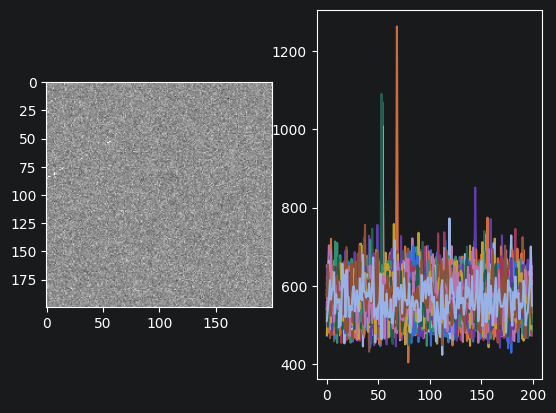

In [93]:
BIAS_DN = 552.0        # bias offset
READ_NOISE_DN = 40.0   # read noise, rms
EM_GAIN = 300.0
E_PER_DN = 3.77        # output-amplifier electrons per DN

my_track = Track('Ash', 8*4, 1000)
my_track.generate_path()
my_track.build_projection(15)
my_track.build_profile()
out = my_track.line_at_angle(30)

rng = np.random.default_rng()
lam = 1
shape = np.shape(out)
lam = np.broadcast_to(lam, shape)
n_pe = rng.poisson(lam)
electrons = rng.gamma(shape=n_pe, scale=EM_Gain)
dn = electrons / E_PER_DN + BIAS_DN + rng.normal(0.0, READ_NOISE_DN, shape)

oute = rng.gamma(shape = out, scale = EM_GAIN)




frame = dn+oute
plt.subplot(1,2,1)
plt.imshow(frame[400:600,200:400], cmap='Greys_r',vmin=285, vmax=875)
plt.subplot(1,2,2)
plt.plot(frame[400:600,220:270])
plt.show()



In [16]:
rng = np.random.default_rng()
lam =1
shape = [100,100]
lam = np.broadcast_to(lam, shape)
n_pe = rng.poisson(lam)
electrons = rng.gamma(shape=n_pe, scale=EM_Gain)
dn = electrons / E_PER_DN + BIAS_DN + rng.normal(0.0, READ_NOISE_DN, shape)

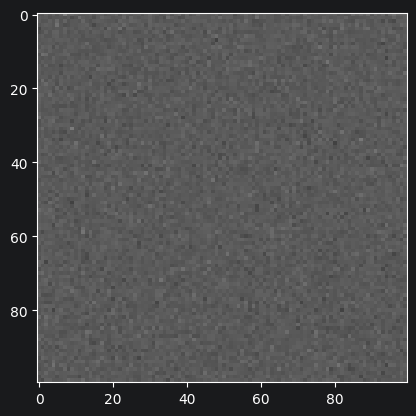

In [17]:
plt.imshow(dn, cmap='Greys_r',vmin=0, vmax=2000)

In [109]:
# Generate track data

def generate_frame(number_frame, NA=0.3, EM_GAIN=300):
    frames = []
    angles = [5,10,15,20]
    rotations = [30,60,120,150,210,240,300,330]
    for I in range(number_frame):
        number_collected = int(356*(NA**2 / (4)))
        BIAS_DN = 552.0        # bias offset
        READ_NOISE_DN = 40.0   # read noise, rms

        #EM_GAIN = 300.0
        E_PER_DN = 3.77        # output-amplifier electrons per DN


        my_track = Track('Ash', number_collected, 1000)
        my_track.generate_path()
        my_track.build_projection(np.random.choice(angles))
        my_track.build_profile()
        out = my_track.line_at_angle(np.random.choice(rotations))

        rng = np.random.default_rng()
        lam = 1
        shape = np.shape(out)
        lam = np.broadcast_to(lam, shape)
        n_pe = rng.poisson(lam)
        electrons = rng.gamma(shape=n_pe, scale=EM_Gain)
        dn = electrons / E_PER_DN + BIAS_DN + rng.normal(0.0, READ_NOISE_DN, shape)
        oute = rng.gamma(shape = out, scale = EM_GAIN) / E_PER_DN
        frame = dn+oute
        frames.append(frame)
    return frames

In [127]:
na = [0.3,0.4,0.5,0.6]
em_GAINE = [100,200,300,400,500,600,700,800]
frames = 10
for NA in na:
    for EM_GAINE in em_GAINE:
        outer = generate_frame(frames,NA,EM_GAINE)
        outer = np.array(outer)
        path = "tracks_"+str(NA)+"_"+str(EM_GAINE)+".tif"
        save_tiff_stack(path, outer, axes="TYX", compress=False)


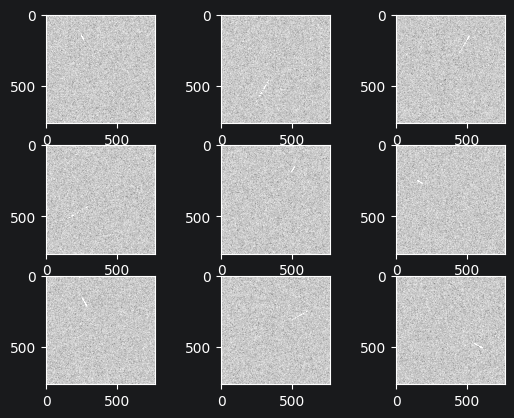

In [125]:
for I in range(1,10):
    plt.subplot(3,3,I)
    plt.imshow(outer[I], cmap='Greys_r',vmin=500, vmax=600)